# Inference Lab: Pricing Under Uncertainty


**Run this notebook in Google Colab.** The `demand` module is compiled for Linux and Python 3.13 only, so it will not import on a Mac or Windows machine.

The goal of this lab is to use what you've learned in this class to find the optimal price for something. You can't know for sure what the underlying curve of revenue vs price looks like. All you know is what you would know in the real world, information you gain by sampling-- you can market test any price using the demand function below. When you set the price, the market test runs for a certain amount of time, and then reports responses-- a list of 1s (bought) and 0s (didn't buy) for that price point. The total number in the sample, $n$, is therefore a random variable, given by `len(responses)`. The number of consumers who buy the product is `responses.sum().` Every time you run a market test, it takes time (literally, it will take a while to run, so don't do this lab last minute!).

In [ ]:
!git clone -q https://github.com/smgroves/demand_lab.git

%cd /content/demand_lab

from demand import demand

responses = demand(price=14.0)

print(len(responses), responses.sum())

/content/demand_lab
140 111


## 1. Compare two prices

Run one market test with price = 30. Then test price = 25. Which price earns more revenue per potential customer?

1. For each price, estimate the proportion $\hat{p}$ of customers who buy, and the revenue per customer $\hat{r}$.
2. Estimate the standard error of each $\hat{r}$ by bootstrapping.
3. Compute a 95% confidence interval for each $\hat{r}$.
4. Compute a 95% confidence interval for the difference $\hat{r}_{25} - \hat{r}_{30}$.
   
5. Interpret the estimates, SEs, and intervals. Report which price earns more profit, and how confident you are.



In [ ]:
# use in the lab (with demand, and prices 25 and 30)
price_A, price_B = 30.0, 25.0
resp_A = demand(price_A)
resp_B = demand(price_B)

In [ ]:
prop_A = resp_A.mean()
prop_B = resp_B.mean()

rev_A = prop_A * price_A
rev_B = prop_B * price_B

print(rev_A)
print(rev_B)

13.728813559322035
9.472049689440993


**A price of \$30 (price_A) earns more estimated revenue per potential customer (\$13.72 compared to \$9.47).**

In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(5030)
# use in the lab
B = 2000

def bootstrap_r(responses, price, B=B):
    """B bootstrap values of r_hat."""
    idx = rng.integers(0, len(responses), size=(B, len(responses)))
    return price * responses[idx].mean(axis=1)

def se_formula(responses, price):
    """SE of r_hat from P * sqrt(p_hat (1 - p_hat) / n)."""
    p = responses.mean()
    return price * np.sqrt(p * (1 - p) / len(responses))

reps_A = bootstrap_r(resp_A, price_A)
reps_B = bootstrap_r(resp_B, price_B)

pd.DataFrame([
    {"price": price_A, "r_hat": price_A * resp_A.mean(),
     "SE (bootstrap)": reps_A.std(ddof=1), "SE (formula)": se_formula(resp_A, price_A)},
    {"price": price_B, "r_hat": price_B * resp_B.mean(),
     "SE (bootstrap)": reps_B.std(ddof=1), "SE (formula)": se_formula(resp_B, price_B)},
]).round(3)

,price,r_hat,SE (bootstrap),SE (formula)
0,30.0,13.729,1.112,1.123
1,25.0,9.472,0.959,0.956


In [ ]:
# use in the lab
def ci_table(pairs):
    rows = []
    for P, resp, reps in pairs:
        r_hat, se = P * resp.mean(), se_formula(resp, P)
        lo_b, hi_b = np.percentile(reps, [2.5, 97.5])
        rows.append({"price": P, "n": len(resp), "r_hat": round(r_hat, 2),
                     "95% CI (bootstrap)": f"({lo_b:.2f}, {hi_b:.2f})",
                     "95% CI (r_hat ± 1.96 SE)": f"({r_hat - 1.96 * se:.2f}, {r_hat + 1.96 * se:.2f})"})
    return pd.DataFrame(rows)

ci_table([(price_A, resp_A, reps_A), (price_B, resp_B, reps_B)])

,price,n,r_hat,95% CI (bootstrap),95% CI (r_hat ± 1.96 SE)
0,30.0,177,13.73,"(11.36, 15.76)","(11.53, 15.93)"
1,25.0,161,9.47,"(7.61, 11.34)","(7.60, 11.35)"


In [ ]:
# use in the lab
def diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B):
    """95% CI for r_A - r_B, from the bootstrap and from the formula."""
    d = price_A * resp_A.mean() - price_B * resp_B.mean()
    boot = tuple(np.percentile(reps_A - reps_B, [2.5, 97.5]))
    se = np.sqrt(se_formula(resp_A, price_A) ** 2 + se_formula(resp_B, price_B) ** 2)
    return d, boot, (d - 1.96 * se, d + 1.96 * se)

def verdict(lo, hi, name_A, name_B):
    if lo > 0:
        return f"{name_A} earns more"
    if hi < 0:
        return f"{name_B} earns more"
    return "can't tell (interval contains 0)"

d, boot, z = diff_ci(resp_A, price_A, reps_A, resp_B, price_B, reps_B)
print(f"r_30 - r_25 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$30', '$25')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$30', '$25')}")

r_30 - r_25 = 4.26
  95% CI, bootstrap: (1.23, 7.21)  ->  $30 earns more
  95% CI, formula:   (1.37, 7.15)  ->  $30 earns more


**Estimates:** \$13.73 in revenue per potential customer for a \$30 set price. \$9.47 in revenue per potential customer for a \$25 set price. The esimate for price A is larger.

**SE:** 68\% of the estimated revenues of the boostrapped samples for \$30 fall in the range of \$13.73 - 1.112 to \$13.73 + 1.112. 68\% of the estimated revenues of the boostrapped samples for \$25 fall in the range of \$9.47 - 0.959 to \$9.47 + 0.959. These standard errors are estimates of the standard deviation of the sampling distribution of mean revenue per potential customer at these prices.

**Interval (single):** If we were to repeat this market test 100 times, we would expect 95 of those intervals to contain the true revenue per potential customer. This interval ranges from \$11.36 to \$15.76 for a set price of \$30. For a set price of \$25, this interval ranges from \$7.61 to \$11.34. These intervals represent the range of plausible values for our true revenue per potential customer given our samples at these prices. (with 95% confidence)

**Interval (difference):** If we were to repeat this market test 100 times, we would expect 95 of those intervals to contain the true difference in revenue per potential customer between price A and price B. This interval ranges from \$1.23 to \$7.21. Since this interval does not contain 0, we can reject the null hypothesis and say that there is a significant difference between projected revenue with set price A (\$30) and set price B (\$25).

**Which is more profitable:** In the single market test, we saw that price A yielded more revenue. Additionally, because our 95% confidence interval of the difference in revenue between price A and price B does not contain 0, we have evidence to support that price A is more profitable than the price B.

## 2. The cost of sampling

7. Run a second market test at each price. Pool the two price = 30 samples (`np.concatenate`), and pool the two price = 25 samples.
8. Recompute the SEs, the intervals, and the interval for the difference. By roughly what factor did the SE shrink? Explain why, using the SE formula.
   
9.  **Was the extra sampling worth it?** Every market test takes time, and while you're testing you aren't selling at your best price, so each test costs the company revenue. Did the first round already settle the question (its difference interval excluded 0)? If so, the second round cost time and bought nothing but a narrower interval. If not, did the second round settle it?


In [ ]:
# use in the lab
pool_A = np.concatenate([resp_A, demand(price_A)])
pool_B = np.concatenate([resp_B, demand(price_B)])
pool_reps_A = bootstrap_r(pool_A, price_A)
pool_reps_B = bootstrap_r(pool_B, price_B)

print(f"SE ratio (pooled / one test), bootstrap: ${price_A:g}: {pool_reps_A.std(ddof=1) / reps_A.std(ddof=1):.2f}, "
      f"${price_B:g}: {pool_reps_B.std(ddof=1) / reps_B.std(ddof=1):.2f};  1/sqrt(2) = {1 / np.sqrt(2):.2f}")

d, boot, z = diff_ci(pool_A, price_A, pool_reps_A, pool_B, price_B, pool_reps_B)
print(f"pooled r_30 - r_25 = {d:.2f}")
print(f"  95% CI, bootstrap: ({boot[0]:.2f}, {boot[1]:.2f})  ->  {verdict(*boot, '$30', '$25')}")
print(f"  95% CI, formula:   ({z[0]:.2f}, {z[1]:.2f})  ->  {verdict(*z, '$30', '$25')}")

SE ratio (pooled / one test), bootstrap: $30: 0.70, $25: 0.67;  1/sqrt(2) = 0.71
pooled r_30 - r_25 = 2.14
  95% CI, bootstrap: (0.15, 4.21)  ->  $30 earns more
  95% CI, formula:   (0.09, 4.18)  ->  $30 earns more


In [ ]:
pool_reps_A.std(ddof=1)

np.float64(0.7831701782563454)

In [ ]:
pool_reps_B.std(ddof=1)

np.float64(0.6462307902169626)

**SE shrinkage:** The formula for SE is sqrt(s^2)/sqrt(n). If you double the size of n, you cut the SE by 1/sqrt(2) = 0.71. This is further shown by looking at the SE ratios for both prices; both are around 0.71 (\$30: 0.70, \$25: 0.67)

**Extra sampling?:** The first round of intervals did already settle the question since the confidence interval excluded 0. Therefore, the second round only cost time and bought nothing but a narrower confidence interval so we would say it was not worth the extra sampling.

## 3. Finding the optimal price

Now find the price that maximizes revenue per customer. Search prices between about \$5 and \$100.

Every market test takes time, and time spent testing is revenue lost: while you test, you aren't selling at your best price. Your confidence intervals tell you whether another test is worth running. **Use as few market tests as you can (<25 would be good).** Your grade will be based on, in this order, whether you:
- accurately used the information you have by accurately interpreting confidence intervals
- found a good price, close to the optimal price
- and used fewer tests.

If this sounds fun to you, run with it! If you are still very confused about what to do, read the hints below.

<details><Summary>Hints</summary>
<b>Hint 1:</b> There are a few ways you could search:

- Brute force: test every price on a fine grid. This takes a market test at every price, including prices that are obviously bad. This would be a bad choice.
- Hill climbing: compare the CI for two prices, move toward the better one, and repeat. For example, start from the 25/30 comparison above; based on which price is better, choose another price \$10 away in that direction (15 if 25 was better; 40 if 30 was better). Shrink the step size as you get close to a good price. If you can't detect a difference between two prices, either shrink the step size or increase the sample size (i.e. run another market test at the same price).
- other strategies that I won't mention here.
  
<b>Hint 2:</b> You may want to try starting your tests with a few different prices across the range; there may be local maxima you will get stuck in if you just hill climb towards a single maximum.

<b>Hint 3:</b> You can make up your own strategy or try a mix of strategies. However, keep in mind that your grade will reflect how well you ran A/B testing and interpreting confidence intervals, more than how complex your strategy is. Similarly, a lucky guess with a brute force strategy would not be a good reproducible strategy.

<b>Hint 4:</b>
Turn your code from part 1 into a function, so you can easily input responses, run bootstrapping, calculate SE, and calculate confidence intervals. Then make another function where you give it two confidence intervals and make a decision based on them: sample more at the same test, or move in one direction with some step size.
   </details>

**Before you run any tests,** write down your plan: which prices you'll test first, how you'll decide where to go next, and what your intervals need to show before you stop. Then follow it, and note anywhere you changed course and why.

For any method, stop when your intervals show that another test is unlikely to change your answer by enough to matter.

**Deliverable:** A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for $r$ at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

**Our plan?**:
Our intial idea is to do a coarse scan of the space with a step size of 20 (5, 20, 40, 60, 80, and 100) for a total of 6 initial market tests. We will then compare the confidence intervals to each other and continue to test ranges of prices that continue to capture larger values for revenue. With our smaller range of profitable prices, we will 'hill-climb' (comparing neighbors) to determine in which direction our peak revenue may be.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

In [ ]:
# use in the lab: run_test(demand, price, data)
data = {}   # price -> list of response arrays, one per market test

def run_test(market, price, data):
    """Run one market test at price, save it, and return all responses at that price so far."""
    data.setdefault(price, []).append(market(price))
    return np.concatenate(data[price])

def tests_run(data):
    """Total number of market tests saved in data."""
    return sum(len(tests) for tests in data.values())

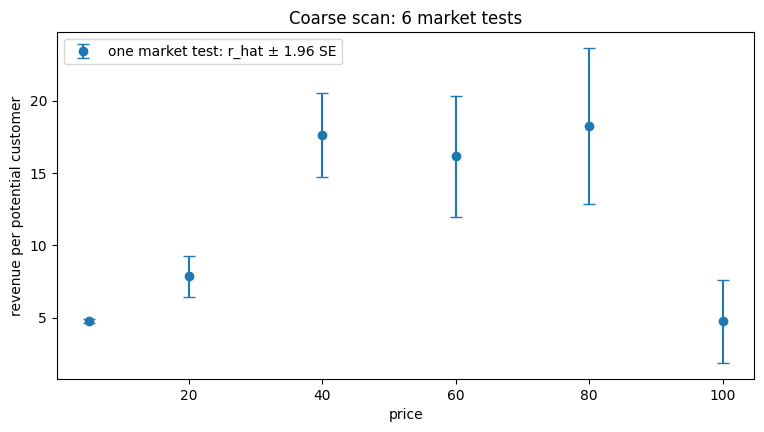

In [ ]:
# use in the lab (except the true-curve line)
scan_prices = np.array([5, 20, 40, 60, 80, 100])
scan = {P: run_test(demand, P, data) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])

grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o", capsize=4, label="one market test: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

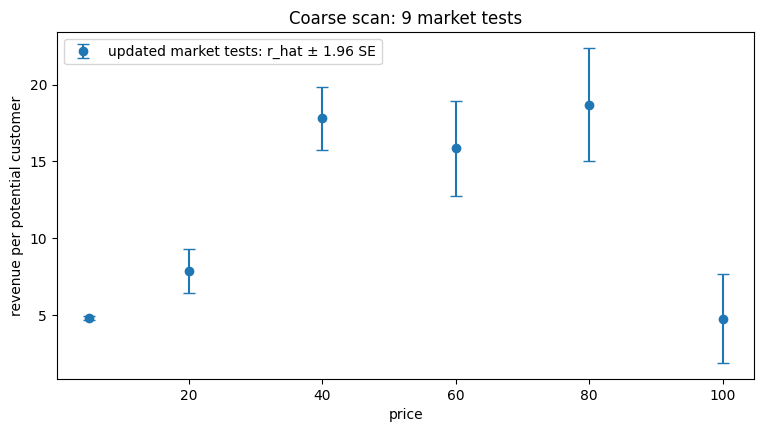

In [ ]:
extra_tests = [40, 60, 80]

for P in extra_tests:
  run_test(demand, P, data)

scan_prices = np.array([5, 20, 40, 60, 80, 100])

scan = {P: np.concatenate(data[P]) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])


grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o", capsize=4, label="updated market tests: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

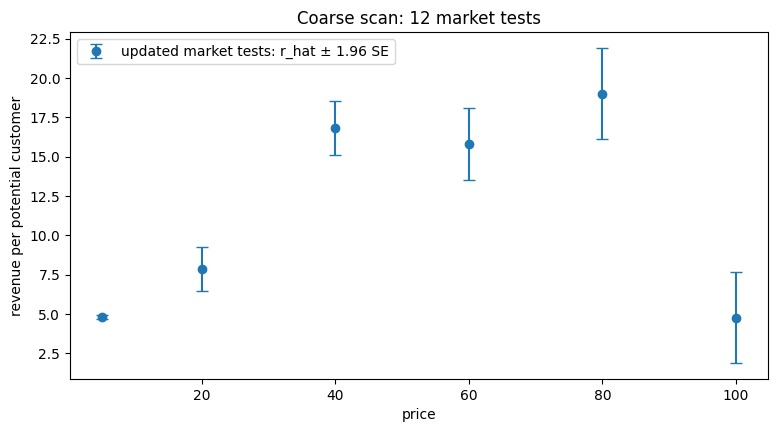

In [ ]:
extra_tests = [40, 60, 80]

for P in extra_tests:
  run_test(demand, P, data)

scan_prices = np.array([5, 20, 40, 60, 80, 100])

scan = {P: np.concatenate(data[P]) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])


grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o", capsize=4, label="updated market tests: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

We will choose to focus our tests around P = 80 because it seems to have the highest point estimate even after repeated market tests.

In [ ]:
def compare_neighbors(market, price, h, data):
    """Test price - h and price + h once more each (pooled with earlier tests),
    and return the 95% CI for r(price + h) - r(price - h)."""
    lo_p, hi_p = price - h, price + h
    low, high = run_test(market, lo_p, data), run_test(market, hi_p, data)
    d = hi_p * high.mean() - lo_p * low.mean()
    se = np.sqrt(se_formula(low, lo_p) ** 2 + se_formula(high, hi_p) ** 2)
    ci = (d - 1.96 * se, d + 1.96 * se)
    move = "raise" if ci[0] > 0 else ("lower" if ci[1] < 0 else "can't tell")
    return {"price": price, "compared": f"${lo_p:g} vs ${hi_p:g}", "difference": d,
            "ci_low": ci[0], "ci_high": ci[1], "slope": d / (2 * h), "move": move}

comparisons = pd.DataFrame([compare_neighbors(demand, P, 5.0, data) for P in [80]])
print(f"market tests so far: {tests_run(data)}")
comparisons.round(2)

market tests so far: 14


,price,compared,difference,ci_low,ci_high,slope,move
0,80,$75 vs $85,-4.68,-12.27,2.92,-0.47,can't tell


Since our comparison returned "can't tell", we will widen the interval centered around 80.

In [ ]:
comparisons = pd.DataFrame([compare_neighbors(demand, P, 7.0, data) for P in [80]])
print(f"market tests so far: {tests_run(data)}")
comparisons.round(2)

market tests so far: 16


,price,compared,difference,ci_low,ci_high,slope,move
0,80,$73 vs $87,-1.93,-9.06,5.21,-0.14,can't tell


In [ ]:
comparisons = pd.DataFrame([compare_neighbors(demand, P, 5.0, data) for P in [75]])
print(f"market tests so far: {tests_run(data)}")
comparisons.round(2)

market tests so far: 18


,price,compared,difference,ci_low,ci_high,slope,move
0,75,$70 vs $80,-0.73,-6.13,4.67,-0.07,can't tell


Though our tests did not tell us where to move from these prices, the difference and slope being so low between P = 70 and P = 80 seems to suggest a peak in between these values. So we will narrow the interval and test around prices in between 70 and 80.

In [ ]:
comparisons = pd.DataFrame([compare_neighbors(demand, P, 2.0, data) for P in [72]])
print(f"market tests so far: {tests_run(data)}")
comparisons.round(2)

market tests so far: 20


,price,compared,difference,ci_low,ci_high,slope,move
0,72,$70 vs $74,-2.89,-7.72,1.94,-0.72,can't tell


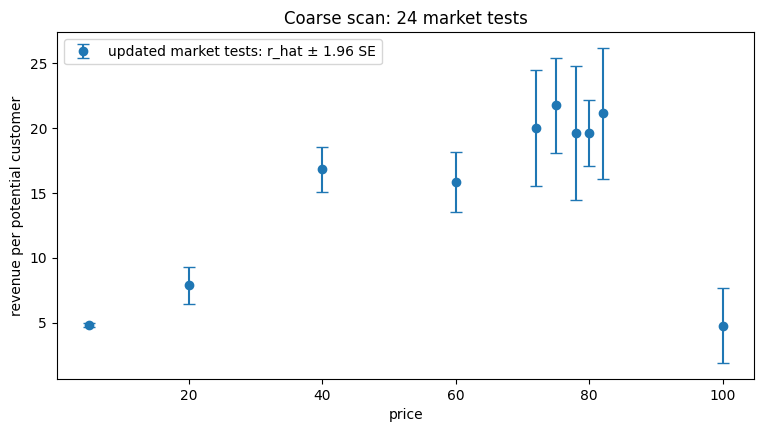

In [ ]:
extra_tests = [72, 75, 78, 82]

for P in extra_tests:
  run_test(demand, P, data)

scan_prices = np.array([5, 20, 40, 60, 72, 75, 78, 80, 82, 100])

scan = {P: np.concatenate(data[P]) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])


grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o", capsize=4, label="updated market tests: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

Plotting the revenue estimates from our market tests, tells us that there may be a peak at P = 75, demonstrated by the jump in our plot so we will test between 75 and 80 to see if the comparison will result in "move lower" accompanied by a negative slope.

In [ ]:
comparisons = pd.DataFrame([compare_neighbors(demand, P, 2.50, data) for P in [77.50]])
print(f"market tests so far: {tests_run(data)}")
comparisons.round(2)

market tests so far: 26


,price,compared,difference,ci_low,ci_high,slope,move
0,77.5,$75 vs $80,-0.91,-4.68,2.85,-0.18,can't tell


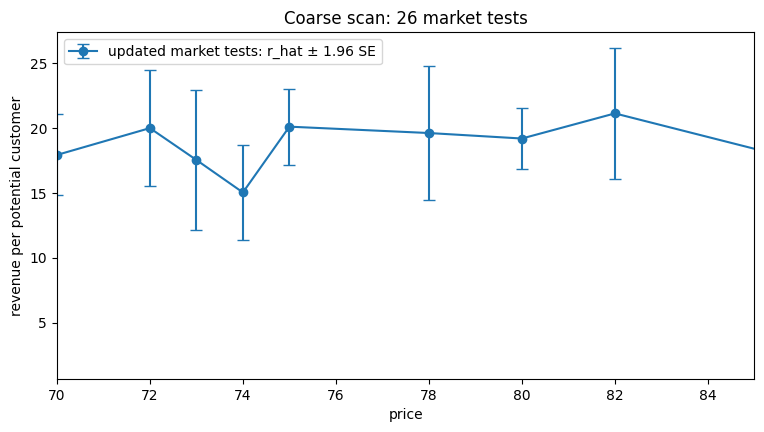

In [ ]:
scan_prices = np.array([5, 20, 40, 60, 70, 72, 73, 74, 75, 78, 80, 82, 100])

scan = {P: np.concatenate(data[P]) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])


grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o-", capsize=4, label="updated market tests: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.xlim(70, 85)
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

After honing in our plot on the values betwee 70 and 85, we will run a few more market tests to narrow some of the Confidence Intervals of the data points in this range.

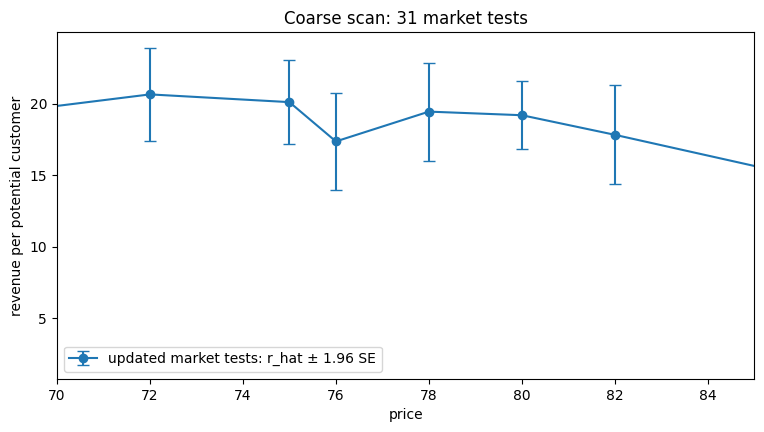

In [ ]:
extra_tests = [72, 76, 76, 78, 82]

for P in extra_tests:
  run_test(demand, P, data)

scan_prices = np.array([5, 20, 40, 60, 72, 75, 76, 78, 80, 82, 100])

scan = {P: np.concatenate(data[P]) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])


grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o-", capsize=4, label="updated market tests: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.xlim(70, 85)
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

This seems to give us a better picture of where the peak could be which is near P = 72 as shown in the plot below.

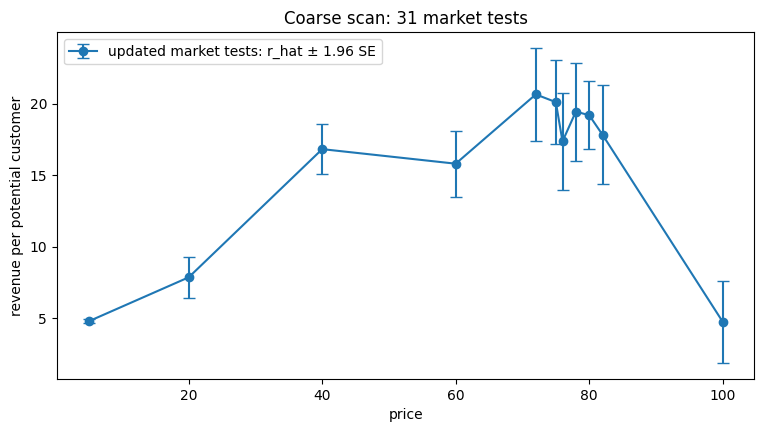

In [ ]:
scan_prices = np.array([5, 20, 40, 60, 72, 75, 76, 78, 80, 82, 100])

scan = {P: np.concatenate(data[P]) for P in scan_prices}

r_hats = np.array([P * scan[P].mean() for P in scan_prices])
ses = np.array([se_formula(scan[P], P) for P in scan_prices])


grid = np.linspace(0, 100, 1001)
plt.figure(figsize=(9, 4.5))
plt.errorbar(scan_prices, r_hats, yerr=1.96 * ses, fmt="o-", capsize=4, label="updated market tests: r_hat ± 1.96 SE")
plt.xlabel("price")
plt.ylabel("revenue per potential customer")
plt.legend()
plt.title(f"Coarse scan: {tests_run(data)} market tests")
plt.show()

In [ ]:
# At P = 72,

P = 72

resp = np.concatenate(data[P])

r_hat = P * resp.mean()
se = se_formula(resp, P)
print(f"Estimated revenue per potential customer: ${r_hat}")
print(f"95% CI (r_hat ± 1.96 SE): (${r_hat - 1.96 * se:.2f}, ${r_hat + 1.96 * se:.2f})")

Estimated revenue per potential customer: $20.651162790697676
95% CI (r_hat ± 1.96 SE): ($17.41, $23.90)


## Write Up:

### Strategy:

Our strategy was to first run a coarse scan by conducting market tests at prices of 5, 20, 40, 60, 80 and 100 respectively to cover the range of prices with minimal market tests. From the coarse scan, we narrowed our search to prices whose confidence intervals overlapped with the highest estimate's in our market tests. For us this was prices 40, 60 and 80.

Once we narrowed this down, we conducted further market tests at these price levels to narrow the confidence intervals of estimated revenue at these prices. We then attempted to use the provided code to compare neighbours around our tested price points in order to find a direction to move towards for our peak. Unfortunately, these tests, did not prove useful due to the confidence intervals of the differences containing 0. However, we did notice that the difference and slope between Prices 70 and 80 was almost 0, which led us to believe a peak existed within this range.

Since the neighbours code still gave us market tests at these prices, we included these in our plot and continued to run individual tests in the range of 70 and 80. This led us to pick 72 as the peak after narrowing the confidence intervals of estimates in this range.

These narrower confidence intervals overlapping told us that we were continuing to get relatively high revenue estimates at these prices (except for 74) which told us to stop and choose a reasonable price in this range.

This price level of P = 72, had an estimated revenue per potential customer of \$20.65 with a 95% confidence interval of (\$17.41, \$23.90)

Total number of market tests ran is: 31